# Proyecto Parcial 2 — Procesamiento Digital de Señales
## Diseño interactivo de filtros digitales en el plano Z

**Contenido**

0. Preparación del entorno
1. Núcleo matemático: clase `SistemaZ` (H(z), respuesta en frecuencia, impulso, estabilidad)
2. Herramienta interactiva del plano Z (clics, arrastre, borrado, control de ω)
3. Experimentos: pasa-bajas, pasa-altas, notch y resonancia
4. Explicación: cómo la posición de polos y ceros afecta la respuesta y la estabilidad

**Fundamento.** Para un sistema LTI causal con ceros $z_i$, polos $p_k$ y ganancia $K$:

$$H(z)=K\,\frac{\prod_i (z-z_i)}{\prod_k (z-p_k)},\qquad H(e^{j\omega})=H(z)\Big|_{z=e^{j\omega}}$$

Interpretación geométrica, con $d_{z_i}=|e^{j\omega}-z_i|$ y $d_{p_k}=|e^{j\omega}-p_k|$:

$$|H(e^{j\omega})|=|K|\,\frac{\prod_i d_{z_i}}{\prod_k d_{p_k}},\qquad
\angle H(e^{j\omega})=\sum_i\angle(e^{j\omega}-z_i)-\sum_k\angle(e^{j\omega}-p_k)\;(+\angle K)$$

**Estabilidad (sistema causal):** todos los polos deben cumplir $|p_k|<1$. Con polos sobre $|z|=1$ el sistema es marginalmente estable (y $H(e^{j\omega})$ no está definida en esa frecuencia); con algún $|p_k|>1$ es inestable.

## 0. Preparación del entorno

In [1]:
# Ejecuta esta celda UNA vez. Habilita los gráficos interactivos (clic y arrastre) en Colab.
!pip -q install ipympl
from google.colab import output
output.enable_custom_widget_manager()
print("Listo. IMPORTANTE: si es la primera vez que instalas ipympl en esta sesión, ve a")
print("Entorno de ejecución > Reiniciar sesión y vuelve a ejecutar desde la celda 1 (la instalación ya no hará falta).")

Listo. IMPORTANTE: si es la primera vez que instalas ipympl en esta sesión, ve a
Entorno de ejecución > Reiniciar sesión y vuelve a ejecutar desde la celda 1 (la instalación ya no hará falta).


## 1. Núcleo matemático

`SistemaZ` guarda polos, ceros y $K$. Reglas de diseño:

* Toda raíz compleja se agrega **junto con su conjugada**, así los coeficientes de $H(z)$ son reales.
* $H(e^{j\omega})$ se evalúa directamente con el producto de distancias/ángulos (sin usar `freqz`), y más abajo se **verifica** contra `scipy.signal.freqz`.
* Si hay más ceros que polos, el sistema no sería causal; se agregan polos en $z=0$ (solo introducen un retardo, no cambian la magnitud) y se avisa.
* Si hay un polo sobre el círculo unitario, la magnitud en esa frecuencia se marca como **no definida** (NaN) y no se grafica.
* La respuesta al impulso se calcula con `lfilter` con condiciones iniciales nulas (sistema causal).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy import signal
import textwrap

def fmt(c, d=3):
    c = complex(c)
    if abs(c.imag) < 1e-9:
        return f"{c.real:.{d}g}"
    return f"{c.real:.{d}g}{c.imag:+.{d}g}j"

class SistemaZ:
    def __init__(self, polos=None, ceros=None, K=1.0):
        self.polos = [complex(p) for p in (polos or [])]
        self.ceros = [complex(z) for z in (ceros or [])]
        self.K = float(K)

    # ---------- edición ----------
    def agregar(self, r, tipo):
        r = complex(r)
        lista = self.polos if tipo == 'polo' else self.ceros
        lista.append(r)
        if abs(r.imag) > 1e-9:               # raíz compleja -> agregar conjugada
            lista.append(np.conj(r))

    def agregar_par(self, radio, ang, tipo):
        self.agregar(radio * np.exp(1j * ang), tipo)

    def limpiar(self):
        self.polos.clear(); self.ceros.clear()

    # ---------- función de transferencia ----------
    def _efectivo(self):
        # Si M > N se agregan (M-N) polos en z=0 para que el sistema sea causal
        extra = max(0, len(self.ceros) - len(self.polos))
        return list(self.ceros), list(self.polos) + [0j] * extra, extra

    def coef(self):
        # Coeficientes de H(z)=B(z)/A(z) en potencias DESCENDENTES de z
        z, p, _ = self._efectivo()
        num = self.K * np.atleast_1d(np.real(np.poly(z)))
        den = np.atleast_1d(np.real(np.poly(p)))
        return num, den

    def coef_zinv(self):
        # Forma en z^-1 (la que usa lfilter): b tiene N+1 términos (rellena con ceros a la izquierda)
        num, den = self.coef()
        b = np.concatenate([np.zeros(len(den) - len(num)), num])
        return b, den

    # ---------- respuesta en frecuencia ----------
    def H(self, w):
        w = np.asarray(w, dtype=float)
        ejw = np.exp(1j * w)
        z, p, _ = self._efectivo()
        num = self.K * np.ones_like(ejw, dtype=complex)
        for zi in z: num = num * (ejw - zi)
        den = np.ones_like(ejw, dtype=complex)
        for pk in p: den = den * (ejw - pk)
        with np.errstate(divide='ignore', invalid='ignore'):
            Hw = np.where(np.abs(den) < 1e-9, np.nan + 0j, num / den)   # polo sobre el círculo -> no definido
        return Hw

    # ---------- impulso ----------
    def impulso(self, N=60):
        b, a = self.coef_zinv()
        x = np.zeros(N); x[0] = 1.0
        return signal.lfilter(b, a, x)

    # ---------- estabilidad ----------
    def estabilidad(self):
        if not self.polos:
            return "ESTABLE (FIR: no hay polos)"
        rmax = max(abs(p) for p in self.polos)
        if rmax < 1 - 1e-9:  return f"ESTABLE (|p|máx = {rmax:.4f} < 1)"
        if rmax <= 1 + 1e-9: return f"MARGINALMENTE ESTABLE (hay polo en |z|=1; |H| no definida ahí)"
        return f"INESTABLE (|p|máx = {rmax:.4f} > 1)"

    # ---------- geometría ----------
    def geometria(self, w0):
        pt = np.exp(1j * w0)
        dz = [abs(pt - z) for z in self.ceros]
        dp = [abs(pt - p) for p in self.polos]
        return pt, dz, dp

    def normalizar(self, w_ref=None):
        # Ajusta K: |H(w_ref)| = 1; si w_ref es None, el máximo de |H| en [0, pi] será 1
        self.K = 1.0
        w = np.linspace(0, np.pi, 2048) if w_ref is None else np.array([w_ref])
        m = np.nanmax(np.abs(self.H(w))) if len(w) else 1
        if np.isfinite(m) and m > 1e-12:
            self.K = 1.0 / m
        return self.K

def banda_3dB(s):
    # Borde(s) de la banda donde |H| >= max/sqrt(2)
    w = np.linspace(0, np.pi, 8192)
    m = np.abs(s.H(w)); idx = np.where(m >= np.nanmax(m) / np.sqrt(2))[0]
    return w[idx[0]], w[idx[-1]]

### Funciones de graficación (compartidas por la interfaz y los experimentos)

In [3]:
def dibujar_plano(ax, s, w0=None):
    ax.clear()
    t = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(t), np.sin(t), 'k-', lw=1)
    ax.axhline(0, color='gray', lw=.6); ax.axvline(0, color='gray', lw=.6)
    for lista, mk, col, lab in ((s.ceros, 'o', 'tab:blue', 'Ceros'), (s.polos, 'x', 'tab:red', 'Polos')):
        if lista:
            ax.plot([r.real for r in lista], [r.imag for r in lista], mk, color=col, ms=9,
                    mew=2, mfc='none', ls='', label=lab)
            # multiplicidad (raíces repetidas)
            vistos = {}
            for r in lista:
                k = (round(r.real, 5), round(r.imag, 5)); vistos[k] = vistos.get(k, 0) + 1
            for (x, y), n in vistos.items():
                if n > 1: ax.annotate(f"({n})", (x, y), textcoords='offset points', xytext=(7, 7), color=col)
    if w0 is not None:
        pt = np.exp(1j * w0)
        ax.plot(pt.real, pt.imag, 'o', color='tab:green', ms=8, label=r'$e^{j\omega}$')
        for r in s.ceros: ax.plot([pt.real, r.real], [pt.imag, r.imag], '--', color='tab:blue', lw=.7, alpha=.7)
        for r in s.polos: ax.plot([pt.real, r.real], [pt.imag, r.imag], '--', color='tab:red', lw=.7, alpha=.7)
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6); ax.set_aspect('equal')
    ax.set_xlabel('Re{z}'); ax.set_ylabel('Im{z}'); ax.set_title('Plano Z')
    ax.grid(alpha=.3)
    if s.ceros or s.polos or w0 is not None: ax.legend(loc='upper right', fontsize=8)

def dibujar_respuestas(axm, axp, axi, s, w0=None, db=False, N=60):
    w = np.linspace(0, np.pi, 1024)
    Hw = s.H(w); mag = np.abs(Hw); fin = np.isfinite(Hw)
    ph = np.full_like(w, np.nan); ph[fin] = np.unwrap(np.angle(Hw[fin]))
    axm.clear(); axp.clear(); axi.clear()
    if db:
        with np.errstate(divide='ignore'):
            y = 20*np.log10(np.maximum(mag, 1e-6))
        axm.plot(w, y); axm.set_ylabel('|H| (dB)')
    else:
        y = mag; axm.plot(w, y); axm.set_ylabel(r'$|H(e^{j\omega})|$')
    axm.set_title('Magnitud'); axm.set_xlim(0, np.pi); axm.grid(alpha=.3)
    axp.plot(w, ph, color='tab:orange'); axp.set_xlim(0, np.pi); axp.grid(alpha=.3)
    axp.set_title('Fase'); axp.set_ylabel('∠H (rad)'); axp.set_xlabel('ω (rad/muestra)')
    if w0 is not None and np.isfinite(s.H(w0)):
        h0 = s.H(w0)
        axm.plot([w0], [20*np.log10(max(abs(h0), 1e-6)) if db else abs(h0)], 'o', color='tab:green')
        axm.axvline(w0, color='tab:green', ls=':')
        axp.plot([w0], [np.interp(w0, w[fin], ph[fin])], 'o', color='tab:green'); axp.axvline(w0, color='tab:green', ls=':')
    if len(s.polos) and max(abs(p) for p in s.polos) > 1e-9 and any(abs(abs(p) - 1) < 1e-9 for p in s.polos):
        axm.text(.5, .9, 'polo en |z|=1: |H| no definida', transform=axm.transAxes, ha='center', color='red', fontsize=8)
    h = s.impulso(N); n = np.arange(N)
    axi.stem(n, h, basefmt=' '); axi.set_title(f'Respuesta al impulso h[n] ({N} muestras)')
    axi.set_xlabel('n'); axi.set_ylabel('h[n]'); axi.grid(alpha=.3)

def texto_sistema(s, w0=None):
    z, p, extra = s._efectivo()
    num, den = s.coef()
    L = []
    L.append("H(z) = K · Π(z − zᵢ) / Π(z − pₖ)")
    L.append(f"K = {s.K:.5g}")
    L.append("Ceros : " + (", ".join(fmt(c) for c in s.ceros) or "(ninguno)"))
    L.append("Polos : " + (", ".join(fmt(c) for c in s.polos) or "(ninguno)"))
    if extra: L.append(f"AVISO: más ceros que polos -> se agregaron {extra} polo(s) en z=0 (retardo) para tener un sistema causal.")
    nf = "".join(f"(z − ({fmt(c)}))" for c in z) or "1"
    df = "".join(f"(z − ({fmt(c)}))" for c in p) or "1"
    L.append("Forma factorizada:")
    L.append(textwrap.fill(f"H(z) = {s.K:.4g} · {nf} / [{df}]", 110, subsequent_indent="    "))
    L.append("Numerador B(z) (potencias descendentes de z): " + np.array2string(num, precision=4, suppress_small=True))
    L.append("Denominador A(z) (potencias descendentes de z): " + np.array2string(den, precision=4, suppress_small=True))
    L.append("Estabilidad (causal): " + s.estabilidad())
    if w0 is not None:
        pt, dz, dp = s.geometria(w0)
        Hv = s.H(w0)
        L.append(f"--- ω = {w0:.3f} rad  (e^jω = {fmt(pt)}) ---")
        L.append("Distancias a los ceros : " + (", ".join(f"{d:.3f}" for d in dz) or "-"))
        L.append("Distancias a los polos : " + (", ".join(f"{d:.3f}" for d in dp) or "-"))
        if np.isfinite(Hv):
            L.append(f"|H| = {abs(Hv):.4f}   ∠H = {np.angle(Hv):.4f} rad   (H = {fmt(Hv, 4)})")
            ch = abs(s.K) * np.prod(dz) / np.prod(dp) if len(dp) else abs(s.K) * np.prod(dz)
            if extra == 0: L.append(f"Verificación K·Πd_z/Πd_p = {ch:.4f}")
        else:
            L.append("|H| NO DEFINIDA (polo sobre el círculo unitario)")
    return "\n".join(L)

def mostrar(s, titulo="", w0=None, db=False, N=60):
    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(2, 3, figure=fig, width_ratios=[1.1, 1, 1])
    axz = fig.add_subplot(gs[:, 0]); axm = fig.add_subplot(gs[0, 1]); axp = fig.add_subplot(gs[1, 1]); axi = fig.add_subplot(gs[:, 2])
    dibujar_plano(axz, s, w0); dibujar_respuestas(axm, axp, axi, s, w0, db, N)
    fig.suptitle(titulo, fontsize=13); fig.tight_layout(); plt.show()
    print(texto_sistema(s, w0))

### Verificación del núcleo contra `scipy.signal`

In [4]:
# Prueba: el H(e^jw) calculado con productos de distancias debe coincidir con scipy.signal.freqz
s = SistemaZ(K=0.7); s.agregar(0.6+0.4j, 'polo'); s.agregar(-0.3, 'polo'); s.agregar(-1, 'cero'); s.agregar(0.5j, 'cero')
num, den = s.coef()
w = np.linspace(0, np.pi, 512)
_, Hs = signal.freqz(num, den, worN=w)          # freqz usa B(z)/A(z) en potencias de z^-1 normalizadas igual
print("Error máx. |H_propia - H_freqz| =", np.max(np.abs(s.H(w) - Hs)))
x = np.zeros(40); x[0] = 1
print("Coeficientes reales:", np.isrealobj(num) and np.isrealobj(den))

Error máx. |H_propia - H_freqz| = 3.7682219008410606e-15
Coeficientes reales: True


## 2. Herramienta interactiva del plano Z

**Cómo usarla**

| Modo | Acción |
|---|---|
| **Polo ×** / **Cero ○** | Clic en el plano Z para colocar la raíz. Si es compleja se agrega su conjugada automáticamente. Un clic cerca del eje real (|Im|<0.04) coloca una raíz real. |
| **Mover** | Arrastra una raíz. Un par conjugado se mueve en simultáneo; una raíz real se mantiene sobre el eje real. |
| **Borrar** | Clic sobre una raíz (se borra también su conjugada). |

Controles: **K**, **ω** (mueve el punto $e^{j\omega}$ sobre el círculo y muestra las distancias a polos/ceros), **dB**, **Normalizar K** (máx |H| = 1) y **Limpiar**.
Las gráficas, la H(z), los coeficientes y la estabilidad se actualizan en cada cambio.

In [5]:
try:
    get_ipython().run_line_magic('matplotlib', 'widget')
except Exception as e:
    raise RuntimeError("Matplotlib aún no reconoce ipympl. Ve a 'Entorno de ejecución > Reiniciar sesión' "
                       "y ejecuta todo de nuevo (o usa la alternativa panel_texto() más abajo).") from e
import ipywidgets as widgets
from IPython.display import display

class PlanoZInteractivo:
    RADIO_SEL = 0.12
    def __init__(self, sistema=None):
        self.s = sistema if sistema is not None else SistemaZ()
        self.sel = None
        with plt.ioff():
            self.fig = plt.figure(figsize=(13, 6.2))
        gs = GridSpec(2, 3, figure=self.fig, width_ratios=[1.1, 1, 1])
        self.axs = dict(z=self.fig.add_subplot(gs[:, 0]), mag=self.fig.add_subplot(gs[0, 1]),
                        fase=self.fig.add_subplot(gs[1, 1]), imp=self.fig.add_subplot(gs[:, 2]))
        self.fig.tight_layout()
        for a in ('toolbar_visible', 'header_visible', 'footer_visible'):
            try: setattr(self.fig.canvas, a, False)
            except Exception: pass

        self.modo = widgets.ToggleButtons(options=[('Polo ×', 'polo'), ('Cero ○', 'cero'), ('Mover', 'mover'), ('Borrar', 'borrar')],
                                          value='polo', description='Modo:')
        self.K = widgets.FloatText(value=self.s.K, description='K:', step=0.05, layout=widgets.Layout(width='150px'))
        self.w = widgets.FloatSlider(value=0.8, min=0, max=np.pi, step=0.01, description='ω (rad):',
                                     readout_format='.2f', layout=widgets.Layout(width='420px'))
        self.db = widgets.Checkbox(False, description='Magnitud en dB', indent=False)
        b_norm = widgets.Button(description='Normalizar K', button_style='info')
        b_clear = widgets.Button(description='Limpiar', button_style='danger')
        self.info = widgets.HTML()

        self.K.observe(lambda c: self._set_K(c['new']), names='value')
        self.w.observe(lambda c: self.redibujar(), names='value')
        self.db.observe(lambda c: self.redibujar(), names='value')
        b_norm.on_click(lambda b: self._normalizar()); b_clear.on_click(lambda b: self._limpiar())

        self.fig.canvas.mpl_connect('button_press_event', self.on_press)
        self.fig.canvas.mpl_connect('motion_notify_event', self.on_move)
        self.fig.canvas.mpl_connect('button_release_event', self.on_release)
        self.redibujar()
        self.ui = widgets.VBox([self.modo, widgets.HBox([self.K, self.w, self.db, b_norm, b_clear]), self.fig.canvas, self.info])

    def mostrar(self): display(self.ui)

    # --- utilidades ---
    def _lista(self, tipo): return self.s.polos if tipo == 'polo' else self.s.ceros
    def _cercano(self, z):
        mejor, bd = None, self.RADIO_SEL
        for tipo in ('polo', 'cero'):
            for i, r in enumerate(self._lista(tipo)):
                d = abs(r - z)
                if d < bd: bd, mejor = d, (tipo, i)
        return mejor
    def _pareja(self, lista, i):
        r = lista[i]
        if abs(r.imag) < 1e-9: return None
        for j, q in enumerate(lista):
            if j != i and abs(q - np.conj(r)) < 1e-6: return j
        return None

    def _set_K(self, v):
        self.s.K = float(v); self.redibujar()
    def _normalizar(self):
        self.K.value = self.s.normalizar(); self.redibujar()
    def _limpiar(self):
        self.s.limpiar(); self.redibujar()

    # --- eventos del ratón ---
    def on_press(self, ev):
        if ev.inaxes is not self.axs['z'] or ev.button != 1: return
        z = complex(ev.xdata, ev.ydata)
        modo = self.modo.value
        if modo in ('polo', 'cero'):
            if abs(z.imag) < 0.04: z = complex(z.real, 0.0)
            self.s.agregar(z, modo)
        elif modo == 'mover':
            c = self._cercano(z)
            if c:
                tipo, i = c; self.sel = (tipo, i, self._pareja(self._lista(tipo), i))
        elif modo == 'borrar':
            c = self._cercano(z)
            if c:
                tipo, i = c; lista = self._lista(tipo); j = self._pareja(lista, i)
                for k in sorted([i] + ([j] if j is not None else []), reverse=True): lista.pop(k)
        self.redibujar()

    def on_move(self, ev):
        if self.sel is None or ev.inaxes is not self.axs['z']: return
        tipo, i, j = self.sel; lista = self._lista(tipo)
        z = complex(ev.xdata, ev.ydata)
        if j is None:
            lista[i] = complex(z.real, 0.0)                       # raíz real: se queda en el eje real
        else:
            if abs(z.imag) < 0.02: z = complex(z.real, 0.0)
            lista[i] = z; lista[j] = np.conj(z)
        self.redibujar()

    def on_release(self, ev):
        self.sel = None

    def redibujar(self):
        w0 = self.w.value
        dibujar_plano(self.axs['z'], self.s, w0)
        dibujar_respuestas(self.axs['mag'], self.axs['fase'], self.axs['imp'], self.s, w0, self.db.value)
        self.info.value = ("<pre style='font-size:12px;line-height:1.25;white-space:pre-wrap'>"
                           + texto_sistema(self.s, w0) + "</pre>")
        self.fig.canvas.draw_idle()

# Sistema inicial de ejemplo (puedes borrarlo con "Limpiar" y empezar de cero)
_s0 = SistemaZ(K=1.0); _s0.agregar(-1, 'cero'); _s0.agregar_par(0.7, np.pi/4, 'polo')
_s0.normalizar(0)
app = PlanoZInteractivo(_s0)
app.mostrar()

### Alternativa sin clics (por si tu sesión de Colab no habilita `ipympl`)

Panel con cuadros de texto: escribe polos y ceros separados por comas (p. ej. `0.6+0.4j, -0.3`; también puedes usar `0.9*np.exp(1j*np.pi/3)`). Se agregan los conjugados automáticamente. **Ejecútala solo si la herramienta de arriba no responde.**

In [6]:
%matplotlib inline
import ipywidgets as widgets
from IPython.display import display

def _parse(txt):
    ns = {"np": np, "pi": np.pi, "j": 1j, "__builtins__": {}}
    out = []
    for tok in [t.strip() for t in txt.split(',') if t.strip()]:
        try: out.append(complex(eval(tok, ns)))
        except Exception as e: print("No pude interpretar:", tok, e)
    return out

def panel_texto():
    t_z = widgets.Text(value='-1, -1', description='Ceros:', layout=widgets.Layout(width='450px'))
    t_p = widgets.Text(value='0.6+0.4j', description='Polos:', layout=widgets.Layout(width='450px'))
    k = widgets.FloatText(value=0.2, description='K:')
    w = widgets.FloatSlider(value=0.8, min=0, max=np.pi, step=0.01, description='ω (rad):', layout=widgets.Layout(width='450px'))
    db = widgets.Checkbox(False, description='dB')
    def f(tz, tp, K, w0, db):
        s = SistemaZ(K=K)
        for r in _parse(tz): s.agregar(r, 'cero')
        for r in _parse(tp): s.agregar(r, 'polo')
        mostrar(s, "Diseño por texto", w0, db)
    out = widgets.interactive_output(f, dict(tz=t_z, tp=t_p, K=k, w0=w, db=db))
    display(widgets.VBox([t_z, t_p, widgets.HBox([k, db]), w, out]))

# panel_texto()   # <- quita el '#' para usarla

## 3. Experimentos

Cada experimento muestra: plano Z, H(z) (factorizada y coeficientes), magnitud y fase de $H(e^{j\omega})$, respuesta al impulso y estabilidad. El diseño se hace ubicando polos y ceros directamente en el plano Z (sin transformación bilineal ni prototipos analógicos).

**Regla de diseño que se usa en los 4 casos:**
* un **cero** cerca (o sobre) el círculo unitario en $\omega_0$ **atenúa** esa frecuencia;
* un **polo** cerca del círculo unitario en $\omega_0$ **resalta** esa frecuencia.

### Experimento 1 — Pasa-bajas
Atenuar frecuencias altas ($\omega\to\pi$, es decir $z=-1$):
* **Ceros dobles en $z=-1$** → $|H(e^{j\pi})|=0$.
* **Par de polos conjugados en $0.6\pm0.4j$** (lado derecho, cerca de $z=1$) → favorece las bajas frecuencias. $|p|=\sqrt{0.52}\approx0.72<1$.
* $K$ normalizada para ganancia 1 en continua ($\omega=0$).

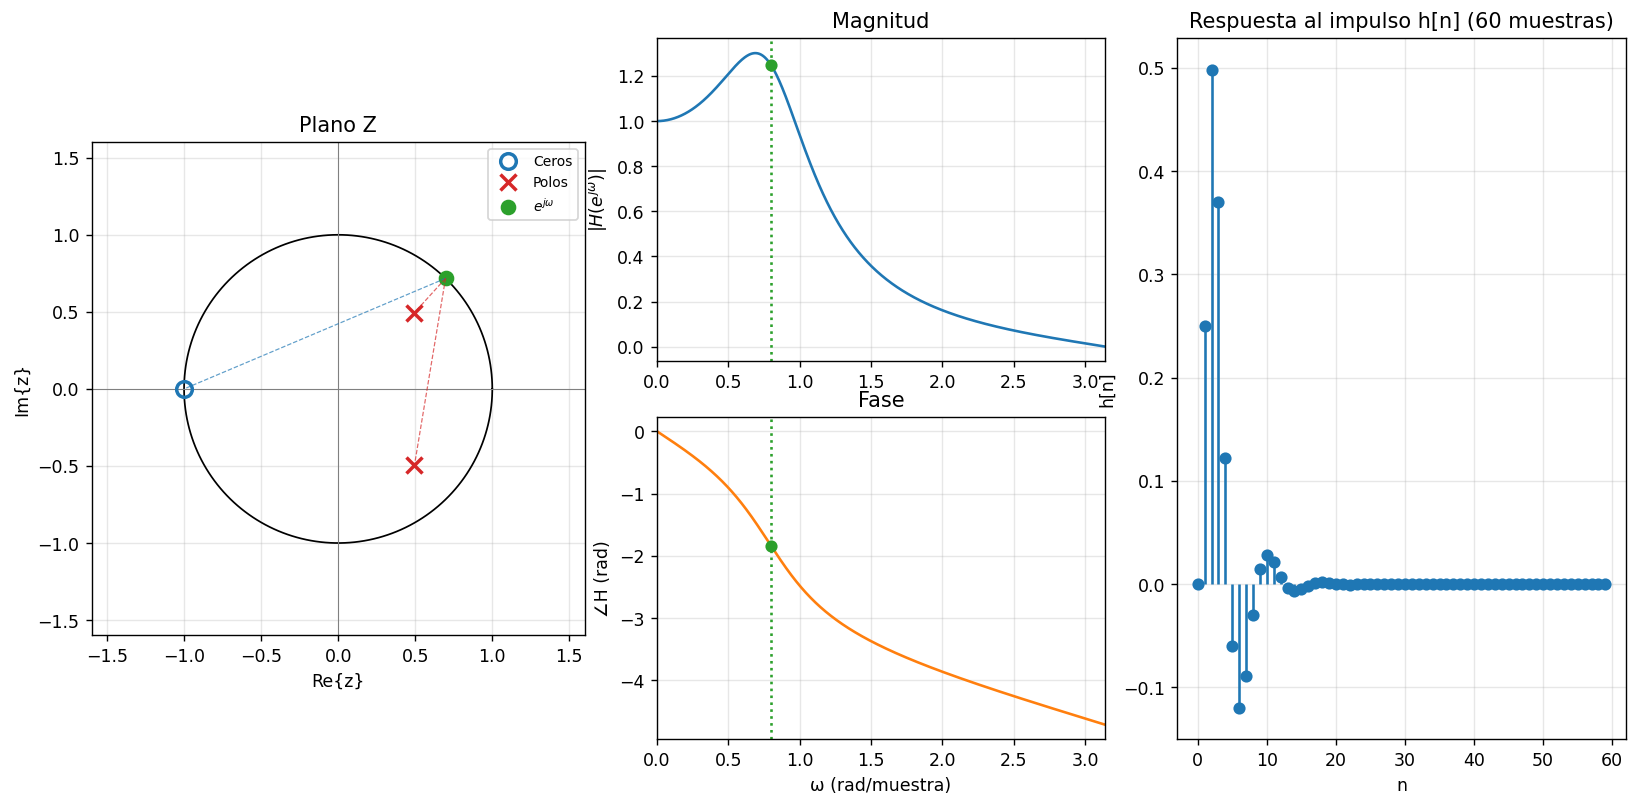

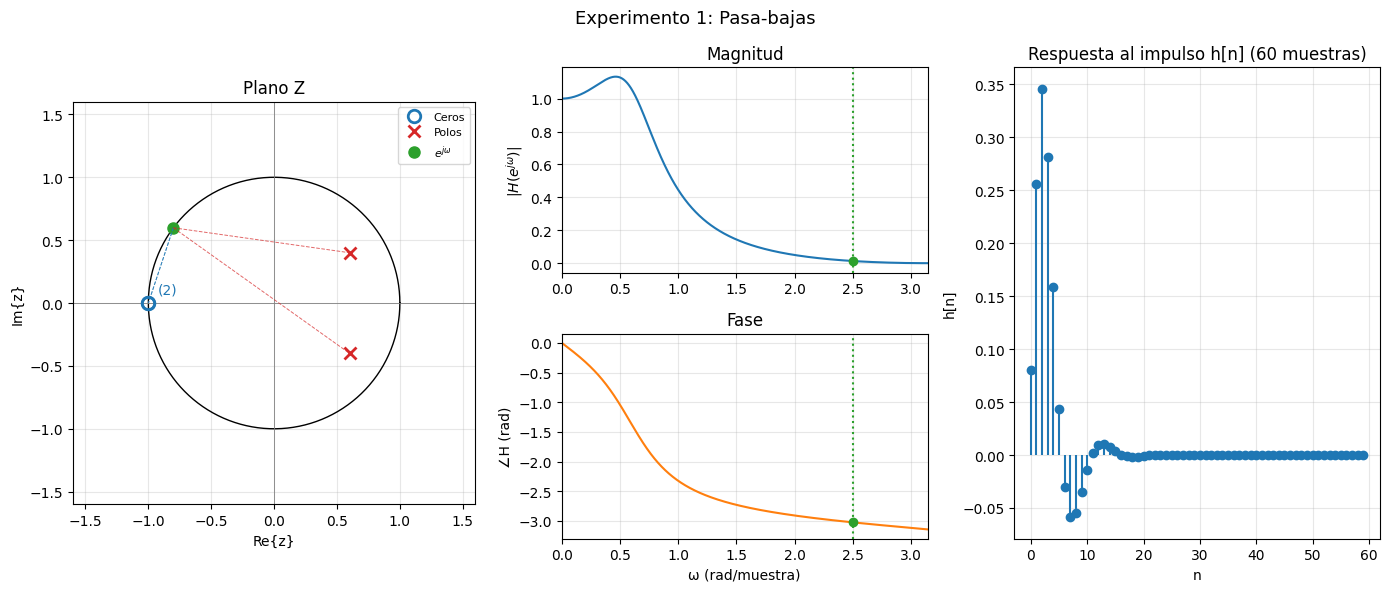

H(z) = K · Π(z − zᵢ) / Π(z − pₖ)
K = 0.08
Ceros : -1, -1
Polos : 0.6+0.4j, 0.6-0.4j
Forma factorizada:
H(z) = 0.08 · (z − (-1))(z − (-1)) / [(z − (0.6+0.4j))(z − (0.6-0.4j))]
Numerador B(z) (potencias descendentes de z): [0.08 0.16 0.08]
Denominador A(z) (potencias descendentes de z): [ 1.   -1.2   0.52]
Estabilidad (causal): ESTABLE (|p|máx = 0.7211 < 1)
--- ω = 2.500 rad  (e^jω = -0.801+0.598j) ---
Distancias a los ceros : 0.631, 0.631
Distancias a los polos : 1.415, 1.721
|H| = 0.0131   ∠H = -3.0233 rad   (H = -0.01298-0.001542j)
Verificación K·Πd_z/Πd_p = 0.0131
Frecuencia de corte (-3 dB) ≈ 0.759 rad/muestra  (= 0.242·π)
Ganancia en ω=0: 1.000 | en ω=π: 4.41e-34


In [7]:
%matplotlib inline
exp1 = SistemaZ()
exp1.agregar(-1, 'cero'); exp1.agregar(-1, 'cero')
exp1.agregar(0.6+0.4j, 'polo')
exp1.normalizar(w_ref=0.0)
mostrar(exp1, "Experimento 1: Pasa-bajas", w0=2.5)
w1, w2 = banda_3dB(exp1)
print(f"Frecuencia de corte (-3 dB) ≈ {w2:.3f} rad/muestra  (= {w2/np.pi:.3f}·π)")
print(f"Ganancia en ω=0: {abs(exp1.H(0.0)):.3f} | en ω=π: {abs(exp1.H(np.pi)):.2e}")

**Observaciones / conclusiones (Exp. 1).**
La magnitud vale 1 en $\omega=0$ y cae hasta 0 en $\omega=\pi$. Cuando $e^{j\omega}$ se acerca a $z=-1$, las distancias a los ceros dobles tienden a 0 y el numerador de $|H|$ se anula; mientras tanto, la distancia a los polos crece, lo que refuerza la caída. Cerca de $\omega=0$ ocurre lo contrario: el punto está cerca de los polos, el denominador es pequeño y la ganancia es alta. La fase es negativa y decrece suavemente (retardo de grupo moderado). La respuesta al impulso es suave, de un solo lóbulo con oscilación amortiguada leve, característica de un filtro que "promedia". Es estable porque $|p|\approx0.72<1$, y h[n] decae a cero.

### Experimento 2 — Pasa-altas
Atenuar frecuencias bajas ($\omega\to0$, es decir $z=1$):
* **Ceros dobles en $z=1$** → $|H(e^{j0})|=0$.
* **Par de polos en $-0.5\pm0.4j$** (lado izquierdo, cerca de $z=-1$) → favorece las altas frecuencias. $|p|\approx0.64$.
* $K$ normalizada para ganancia 1 en $\omega=\pi$.

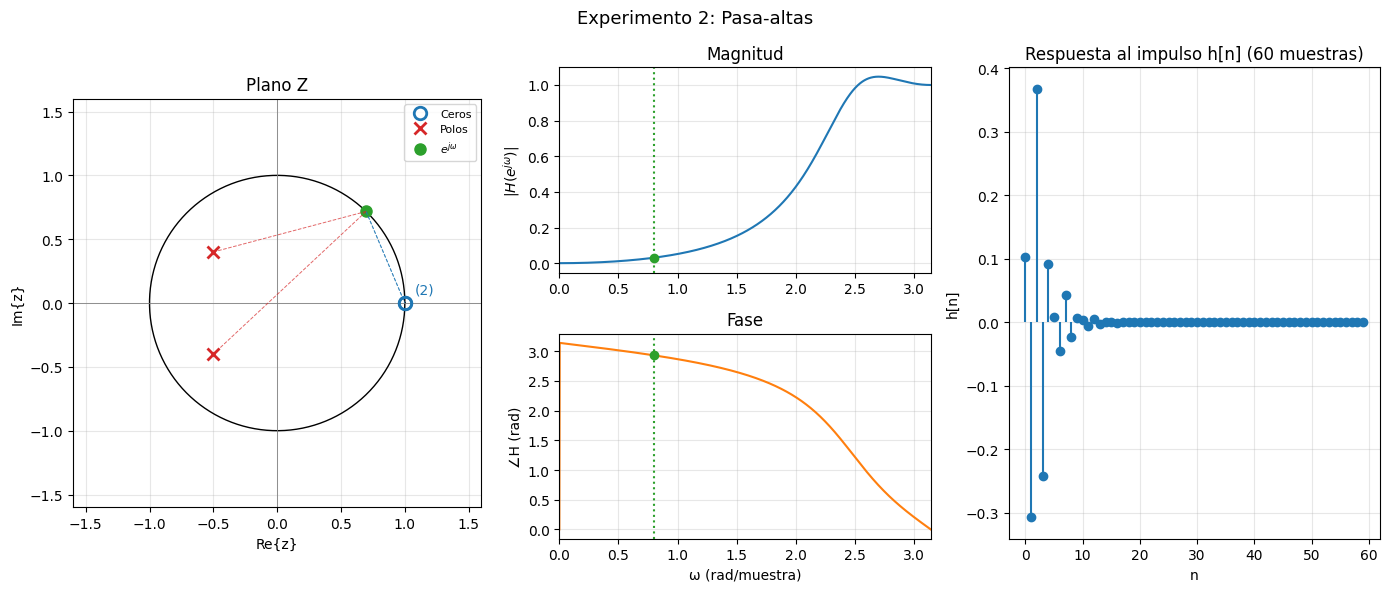

H(z) = K · Π(z − zᵢ) / Π(z − pₖ)
K = 0.1025
Ceros : 1, 1
Polos : -0.5+0.4j, -0.5-0.4j
Forma factorizada:
H(z) = 0.1025 · (z − (1))(z − (1)) / [(z − (-0.5+0.4j))(z − (-0.5-0.4j))]
Numerador B(z) (potencias descendentes de z): [ 0.1025 -0.205   0.1025]
Denominador A(z) (potencias descendentes de z): [1.   1.   0.41]
Estabilidad (causal): ESTABLE (|p|máx = 0.6403 < 1)
--- ω = 0.800 rad  (e^jω = 0.697+0.717j) ---
Distancias a los ceros : 0.779, 0.779
Distancias a los polos : 1.238, 1.637
|H| = 0.0307   ∠H = 2.9312 rad   (H = -0.03+0.006404j)
Verificación K·Πd_z/Πd_p = 0.0307
Frecuencia de corte (-3 dB) ≈ 2.277 rad/muestra  (= 0.725·π)
Ganancia en ω=0: 0.00e+00 | en ω=π: 1.000


In [8]:
%matplotlib inline
exp2 = SistemaZ()
exp2.agregar(1, 'cero'); exp2.agregar(1, 'cero')
exp2.agregar(-0.5+0.4j, 'polo')
exp2.normalizar(w_ref=np.pi)
mostrar(exp2, "Experimento 2: Pasa-altas", w0=0.8)
w1, w2 = banda_3dB(exp2)
print(f"Frecuencia de corte (-3 dB) ≈ {w1:.3f} rad/muestra  (= {w1/np.pi:.3f}·π)")
print(f"Ganancia en ω=0: {abs(exp2.H(0.0)):.2e} | en ω=π: {abs(exp2.H(np.pi)):.3f}")

**Observaciones / conclusiones (Exp. 2).**
Es el espejo del pasa-bajas: reflejar las raíces respecto al eje imaginario ($z\to -z$) transforma $\omega\to\omega+\pi$. Los ceros en $z=1$ eliminan la componente de continua y la magnitud sube hacia $\omega=\pi$, donde los polos (cerca de $z=-1$) amplifican. La respuesta al impulso **alterna de signo** (por los polos con parte real negativa), señal típica de contenido de alta frecuencia, y decae porque el sistema es estable ($|p|\approx0.64<1$).

### Experimento 3 — Notch (rechazo de una frecuencia)
Frecuencia a rechazar: $\omega_0=\pi/3$.
* **Ceros sobre el círculo unitario** en $e^{\pm j\omega_0}$ → $H(e^{j\omega_0})=0$ exactamente.
* **Polos en el mismo ángulo pero con radio $r<1$**: $r\,e^{\pm j\omega_0}$ → "cancelan" el efecto de los ceros lejos de $\omega_0$, de modo que solo se rechaza una banda estrecha.
* $K$ normalizada para ganancia 1 en continua.

Se compara $r\in\{0.8,\,0.9,\,0.95,\,0.99\}$: cuanto más cerca de 1, más estrecho el notch (pero la respuesta al impulso tarda más en extinguirse).

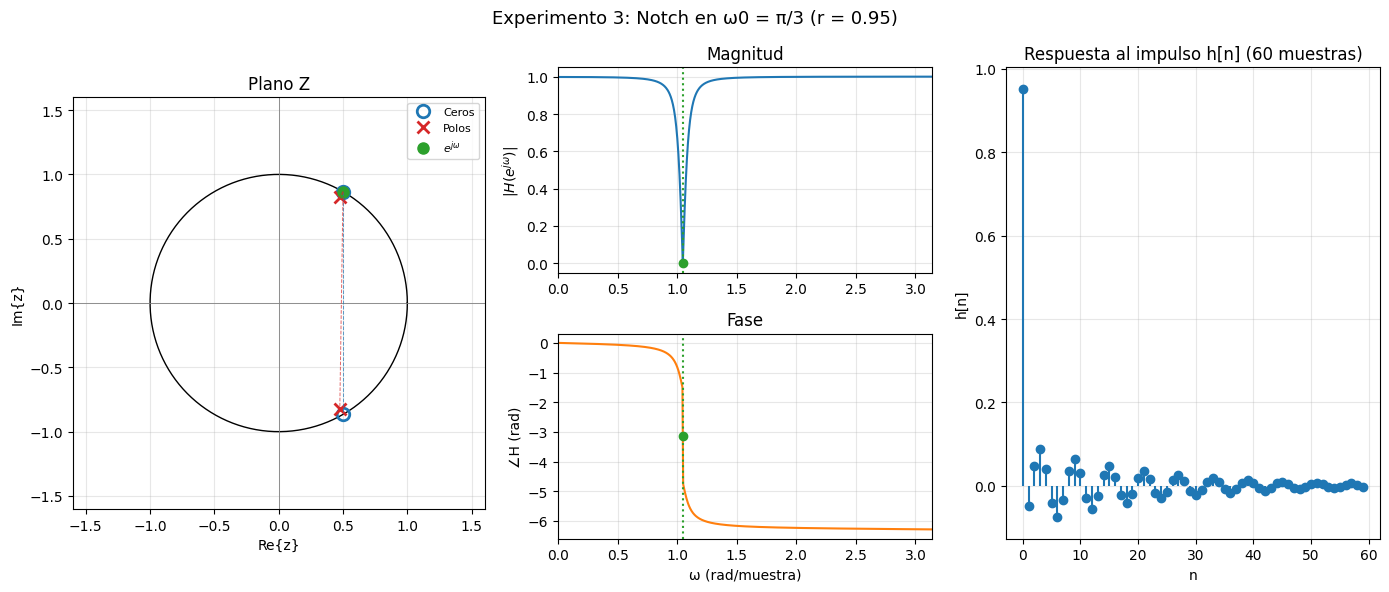

H(z) = K · Π(z − zᵢ) / Π(z − pₖ)
K = 0.9525
Ceros : 0.5+0.866j, 0.5-0.866j
Polos : 0.475+0.823j, 0.475-0.823j
Forma factorizada:
H(z) = 0.9525 · (z − (0.5+0.866j))(z − (0.5-0.866j)) / [(z − (0.475+0.823j))(z − (0.475-0.823j))]
Numerador B(z) (potencias descendentes de z): [ 0.9525 -0.9525  0.9525]
Denominador A(z) (potencias descendentes de z): [ 1.     -0.95    0.9025]
Estabilidad (causal): ESTABLE (|p|máx = 0.9500 < 1)
--- ω = 1.047 rad  (e^jω = 0.5+0.866j) ---
Distancias a los ceros : 0.000, 1.732
Distancias a los polos : 0.050, 1.689
|H| = 0.0000   ∠H = -3.1416 rad   (H = -0)
Verificación K·Πd_z/Πd_p = 0.0000
|H(e^{jω0})| = 0.0


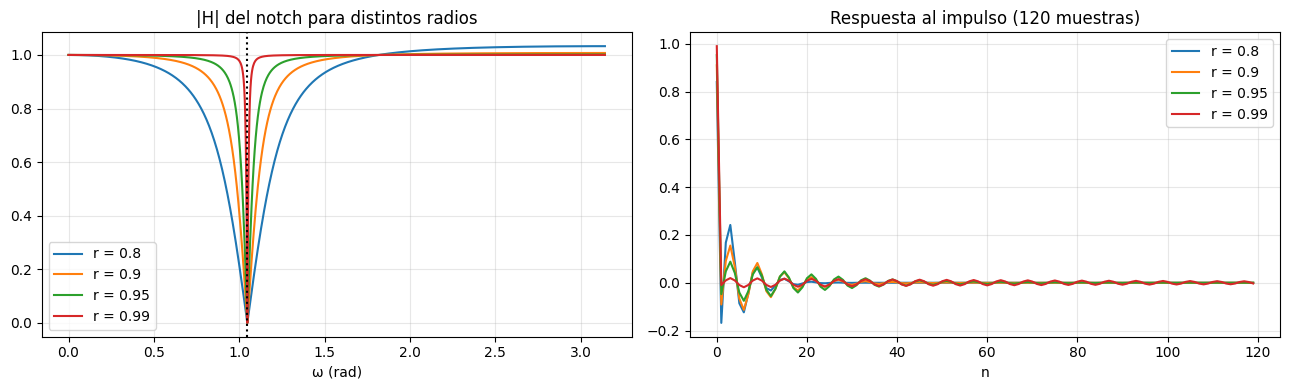

In [9]:
%matplotlib inline
w0n = np.pi/3
def notch(r):
    s = SistemaZ(); s.agregar_par(1.0, w0n, 'cero'); s.agregar_par(r, w0n, 'polo'); s.normalizar(w_ref=0.0); return s

exp3 = notch(0.95)
mostrar(exp3, "Experimento 3: Notch en ω0 = π/3 (r = 0.95)", w0=w0n)
print("|H(e^{jω0})| =", abs(exp3.H(w0n)))

# Comparación del ancho del notch según r
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
w = np.linspace(0, np.pi, 1024)
for r in (0.8, 0.9, 0.95, 0.99):
    s = notch(r)
    a.plot(w, np.abs(s.H(w)), label=f"r = {r}")
    b.plot(s.impulso(120), label=f"r = {r}")
a.set_title("|H| del notch para distintos radios"); a.set_xlabel("ω (rad)"); a.axvline(w0n, color='k', ls=':'); a.legend(); a.grid(alpha=.3)
b.set_title("Respuesta al impulso (120 muestras)"); b.set_xlabel("n"); b.legend(); b.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Observaciones / conclusiones (Exp. 3).**
Con los ceros sobre el círculo unitario en $\omega_0$ la distancia del punto $e^{j\omega_0}$ a ellos es cero, así que $|H|=0$ en esa frecuencia (notch exacto). Fuera de $\omega_0$, el cociente de distancias cero/polo es ≈1 porque cada polo está justo al lado de su cero; por eso la magnitud es plana (≈1) en el resto de la banda. El radio $r$ de los polos controla el ancho: con $r$ más cercano a 1 el notch es más estrecho y selectivo, pero la respuesta transitoria se alarga (polos más cerca del círculo ⇒ h[n] decae más lento, como $r^n$). Siempre $r<1$ para mantener la estabilidad.

### Experimento 4 — Resonancia (efecto del radio de un par de polos conjugados)
Par de polos $r\,e^{\pm j\pi/4}$ con ceros en $z=1$ y $z=-1$ (resonador pasa-banda centrado en $\omega_0=\pi/4$). Se varía **solo el radio $r$** de los polos, con $K=1$:
$r=0.5,\,0.8,\,0.9,\,0.95,\,0.99$ (estables), $r=1$ (marginal) y $r=1.05$ (inestable).

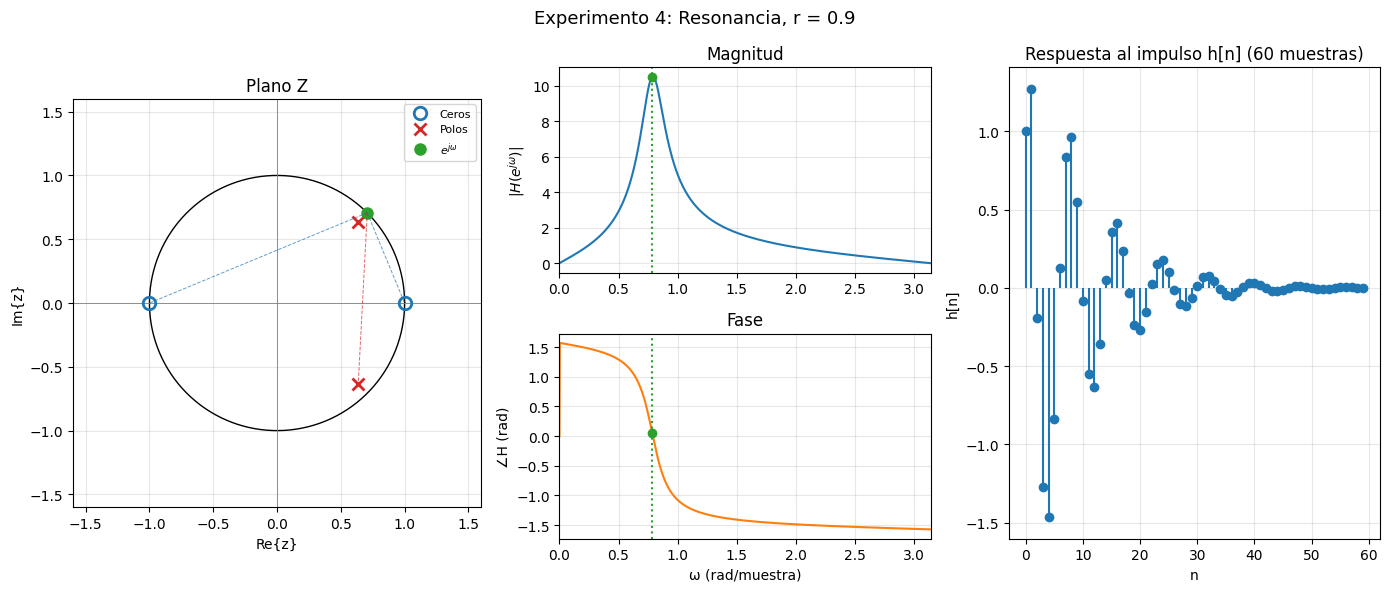

H(z) = K · Π(z − zᵢ) / Π(z − pₖ)
K = 1
Ceros : 1, -1
Polos : 0.636+0.636j, 0.636-0.636j
Forma factorizada:
H(z) = 1 · (z − (1))(z − (-1)) / [(z − (0.636+0.636j))(z − (0.636-0.636j))]
Numerador B(z) (potencias descendentes de z): [ 1.  0. -1.]
Denominador A(z) (potencias descendentes de z): [ 1.     -1.2728  0.81  ]
Estabilidad (causal): ESTABLE (|p|máx = 0.9000 < 1)
--- ω = 0.785 rad  (e^jω = 0.707+0.707j) ---
Distancias a los ceros : 0.765, 1.848
Distancias a los polos : 0.100, 1.345
|H| = 10.5118   ∠H = 0.0526 rad   (H = 10.5+0.5525j)
Verificación K·Πd_z/Πd_p = 10.5118
r = 0.5   pico |H| =    2.67  | ESTABLE (|p|máx = 0.5000 < 1)
r = 0.8   pico |H| =    5.56  | ESTABLE (|p|máx = 0.8000 < 1)
r = 0.9   pico |H| =   10.53  | ESTABLE (|p|máx = 0.9000 < 1)
r = 0.95  pico |H| =   20.51  | ESTABLE (|p|máx = 0.9500 < 1)
r = 0.99  pico |H| =  100.45  | ESTABLE (|p|máx = 0.9900 < 1)


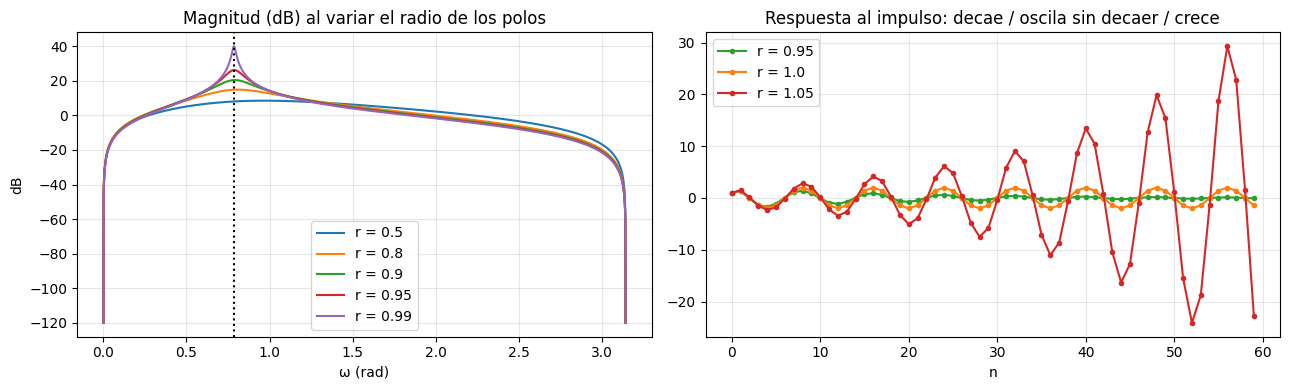

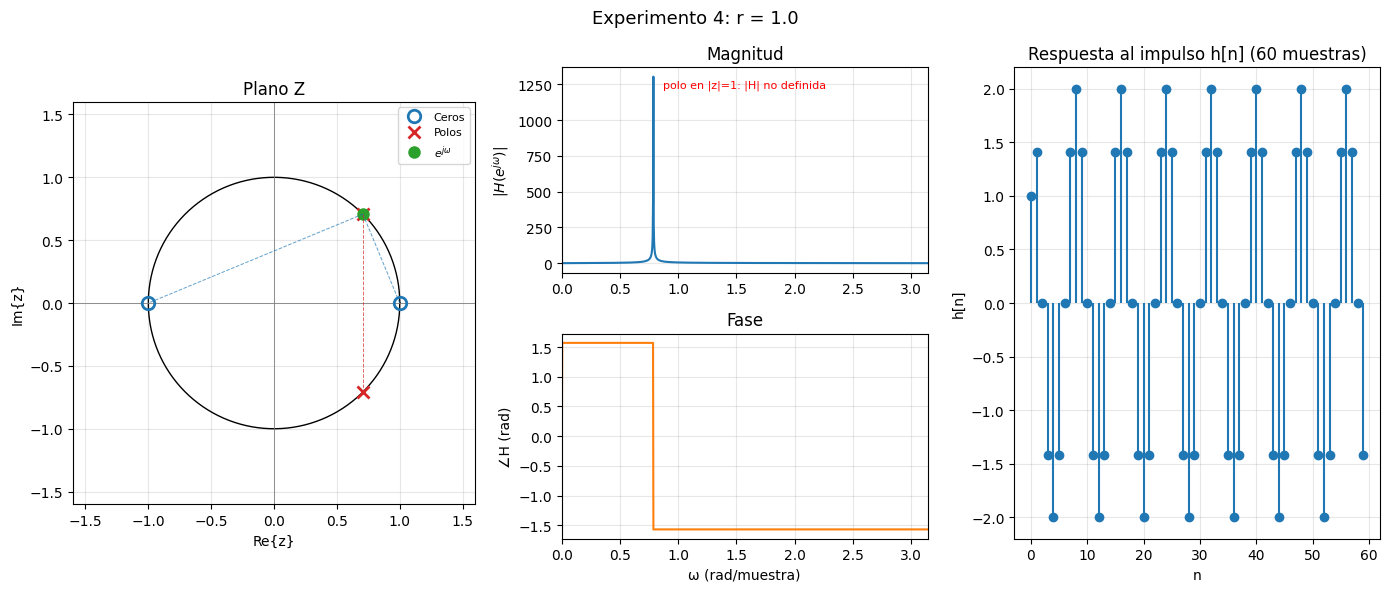

H(z) = K · Π(z − zᵢ) / Π(z − pₖ)
K = 1
Ceros : 1, -1
Polos : 0.707+0.707j, 0.707-0.707j
Forma factorizada:
H(z) = 1 · (z − (1))(z − (-1)) / [(z − (0.707+0.707j))(z − (0.707-0.707j))]
Numerador B(z) (potencias descendentes de z): [ 1.  0. -1.]
Denominador A(z) (potencias descendentes de z): [ 1.     -1.4142  1.    ]
Estabilidad (causal): MARGINALMENTE ESTABLE (hay polo en |z|=1; |H| no definida ahí)
--- ω = 0.785 rad  (e^jω = 0.707+0.707j) ---
Distancias a los ceros : 0.765, 1.848
Distancias a los polos : 0.000, 1.414
|H| NO DEFINIDA (polo sobre el círculo unitario)


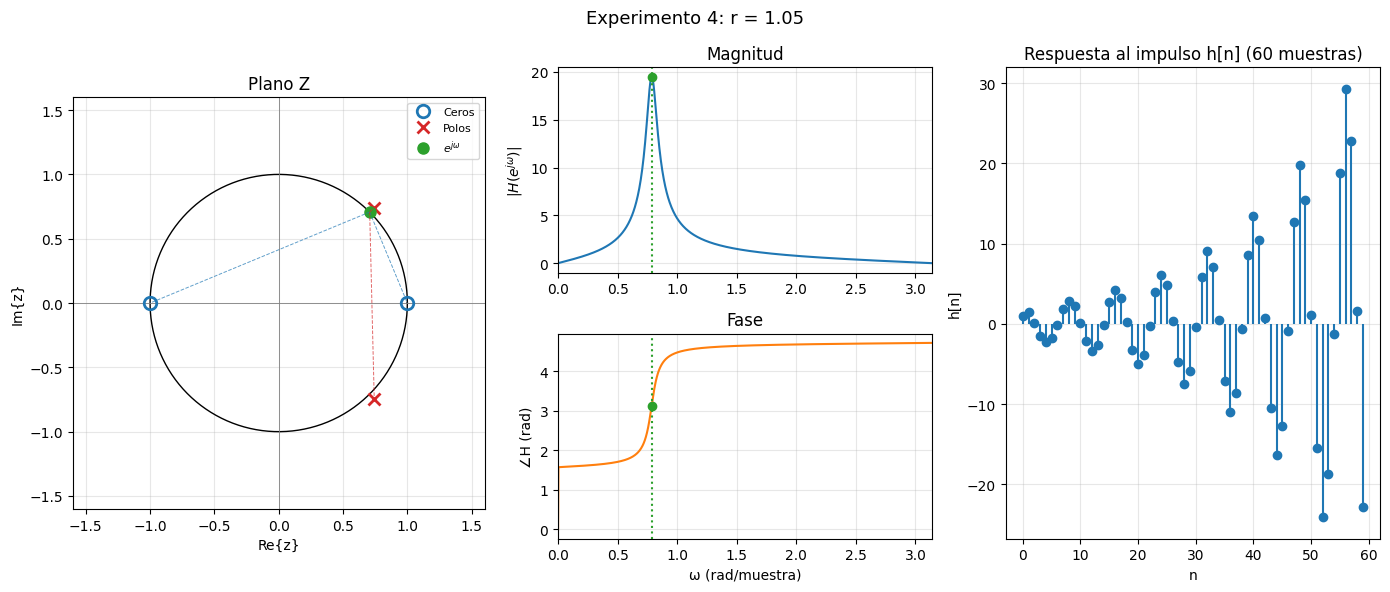

H(z) = K · Π(z − zᵢ) / Π(z − pₖ)
K = 1
Ceros : 1, -1
Polos : 0.742+0.742j, 0.742-0.742j
Forma factorizada:
H(z) = 1 · (z − (1))(z − (-1)) / [(z − (0.742+0.742j))(z − (0.742-0.742j))]
Numerador B(z) (potencias descendentes de z): [ 1.  0. -1.]
Denominador A(z) (potencias descendentes de z): [ 1.     -1.4849  1.1025]
Estabilidad (causal): INESTABLE (|p|máx = 1.0500 > 1)
--- ω = 0.785 rad  (e^jω = 0.707+0.707j) ---
Distancias a los ceros : 0.765, 1.848
Distancias a los polos : 0.050, 1.450
|H| = 19.5064   ∠H = 3.1172 rad   (H = -19.5+0.4756j)
Verificación K·Πd_z/Πd_p = 19.5064


In [10]:
%matplotlib inline
w0r = np.pi/4
def resonador(r):
    s = SistemaZ(K=1.0); s.agregar(1, 'cero'); s.agregar(-1, 'cero'); s.agregar_par(r, w0r, 'polo'); return s

# a) Sistema representativo con el plano Z, H(z), magnitud, fase e impulso
mostrar(resonador(0.9), "Experimento 4: Resonancia, r = 0.9", w0=w0r, db=False)

# b) Barrido del radio
radios = [0.5, 0.8, 0.9, 0.95, 0.99]
w = np.linspace(0, np.pi, 2048)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r in radios:
    s = resonador(r)
    ax[0].plot(w, 20*np.log10(np.maximum(np.abs(s.H(w)), 1e-6)), label=f"r = {r}")
    print(f"r = {r:<5} pico |H| = {np.nanmax(np.abs(s.H(w))):7.2f}  | {s.estabilidad()}")
ax[0].set_title("Magnitud (dB) al variar el radio de los polos"); ax[0].set_xlabel("ω (rad)"); ax[0].set_ylabel("dB")
ax[0].axvline(w0r, color='k', ls=':'); ax[0].legend(); ax[0].grid(alpha=.3)

# c) Estabilidad: r < 1, r = 1, r > 1
N = 60
for r, c in ((0.95, 'tab:green'), (1.0, 'tab:orange'), (1.05, 'tab:red')):
    ax[1].plot(resonador(r).impulso(N), '.-', color=c, label=f"r = {r}")
ax[1].set_title("Respuesta al impulso: decae / oscila sin decaer / crece"); ax[1].set_xlabel("n"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

for r in (1.0, 1.05):
    mostrar(resonador(r), f"Experimento 4: r = {r}", w0=w0r)

**Observaciones / conclusiones (Exp. 4).**
Al acercar los polos al círculo unitario ($r\to1$) la distancia de $e^{j\omega_0}$ al polo disminuye, y como esa distancia está en el denominador, el pico de $|H|$ en $\omega\approx\omega_0$ crece y se hace **más estrecho** (mayor factor de calidad). La fase cambia más abruptamente alrededor de $\omega_0$. Para $r<1$, $h[n]$ es una sinusoide de frecuencia $\omega_0$ con envolvente $r^n$ que decae. Para $r=1$ el polo cae sobre el círculo unitario: $h[n]$ oscila **sin decaer** (marginalmente estable) y $H(e^{j\omega_0})$ **no está definida** (denominador nulo; la gráfica muestra un hueco). Para $r>1$ la envolvente $r^n$ **crece** sin límite: el sistema causal es **inestable**, aunque $H(e^{j\omega})$ siga pudiéndose evaluar en el círculo (esa evaluación no representa una salida acotada).

## 4. Cómo la posición de polos y ceros afecta la respuesta en frecuencia y la estabilidad

* **Ceros.** $|H(e^{j\omega})|$ es proporcional al producto de distancias del punto $e^{j\omega}$ a los ceros. Un cero cerca del círculo unitario en el ángulo $\omega_0$ reduce $|H|$ alrededor de $\omega_0$; si está **sobre** el círculo, $|H(e^{j\omega_0})|=0$ (rechazo total, base del notch). Los ceros en $z=-1$ matan $\omega=\pi$ (pasa-bajas) y los de $z=1$ matan $\omega=0$ (pasa-altas).
* **Polos.** $|H|$ es inversamente proporcional al producto de distancias a los polos. Un polo cerca del círculo en $\omega_0$ produce un pico (resonancia). Cuanto mayor es su radio $r$, más alto y estrecho el pico y más lenta la extinción del transitorio ($h[n]\sim r^n$).
* **Ángulo ↔ frecuencia.** El ángulo de la raíz fija la frecuencia afectada; el radio fija la "intensidad"/selectividad.
* **Fase.** $\angle H=\sum\angle(e^{j\omega}-z_i)-\sum\angle(e^{j\omega}-p_k)$: cambia más rápido cerca de las raíces próximas al círculo.
* **Estabilidad (causal).** BIBO estable ⇔ todos los polos con $|p_k|<1$ (la región de convergencia incluye el círculo unitario). Con $|p|=1$ es marginal y con $|p|>1$ es inestable. Los **ceros no afectan** la estabilidad (pueden ir en cualquier parte), solo la forma de la respuesta.
* **Coeficientes reales.** Las raíces complejas aparecen en pares conjugados, por eso la magnitud es simétrica y la fase antisimétrica respecto a $\omega=0$; basta graficar $0\le\omega\le\pi$.
* **Causalidad.** Si #ceros > #polos, el sistema no es causal; se corrige con polos en $z=0$ (retardos puros) que no alteran la magnitud.